# RQ2: Data Characteristics


In [78]:
import json
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from collections import Counter
import matplotlib.patches as mpatches
import numpy as np


In [79]:
INPUT_JSONL = "../data/parsed_extracted_data.jsonl"

records = []
with open(INPUT_JSONL, "r", encoding="utf-8") as f:
    for line in f:
        records.append(json.loads(line))

df = pd.DataFrame(records)

print(f"Loaded {len(records)} records")
print(records[0].keys())


Loaded 165 records
dict_keys(['Done ?', 'Who?', 'ID', 'Title', 'Authors', 'Venue type', 'Venue', 'Year', 'Task', 'Automation level', 'Model', 'Learning type', 'Model category', 'Model subcategory', 'Training method', 'Input features', 'Pre-processing techniques', 'Encoding techniques', 'Output', 'Dataset availability', 'Dataset', 'Dataset size', 'Language', 'Evaluation type', 'Evaluation method', 'Metrics', 'Baseline', 'Replication package', 'Challenges', 'Remarks', 'Task_Categories'])


In [80]:
# COLOR DEFINITIONS - Matching RQ1 Task Category Colors

# Task category colors from commands.tex (matching RQ1)
TASK_CATEGORY_COLORS = {
    "Pre-Review": "#6D8764",  # Green
    "Assisted": "#7A5195",  # Purple
    "Generative": "#EF5675",  # Pink/Red
    "Evaluation": "#FFA600",  # Orange
}

# Input category colors (complementary palette)
INPUT_CATEGORY_COLORS = {
    "Code-related": "#6D8764",  # Blue
    "Review-related": "#EF5675",  # Purple
    "PR Metadata": "#7A5195",  # Teal
    "Developer metadata": "#FFA600",  # Orange
    "Reviewer metadata": "#0059B1",
}

# Map tasks to their categories (from RQ1 taxonomy)
TASK_TO_CATEGORY = {
    "Pull request assessment": "Pre-Review",
    "Reviewer recommendation": "Pre-Review",
    "Pull request prioritization": "Pre-Review",
    # Assisted
    "Issue/bug detection": "Assisted",
    "Issue type prediction": "Assisted",
    "Comment recommendation": "Assisted",
    # Generative
    "Comment generation": "Generative",
    "Code refinement": "Generative",
    "Data curation": "Generative",
    # Evaluation
    "Comment evaluation": "Evaluation",
    "Sentiment analysis": "Evaluation",
    "Code review gamification": "Evaluation",
}

category_items = {
    "Code-related": [
        "source code",
        "code diff",
        "old code",
        "revised code",
        "Diff Markers",
        "AST",
        "call graph",
        "code image",
    ],
    "Review-related": ["comment", "comment metadata"],
    "PR Metadata": ["PR metadata", "commit message", "issue type", "Old code metadata"],
    "Developer metadata": ["developer metadata"],
    "Reviewer metadata": ["Reviewer metadata"],
}


In [81]:
# 1.1 Extract and Count Input Features

all_inputs = []
for inputs in df["Input features"]:
    if isinstance(inputs, list):
        all_inputs.extend(inputs)
    elif inputs:
        all_inputs.append(inputs)

input_counts = Counter(all_inputs)

print("=" * 60)
print("INPUT FEATURE FREQUENCY")
print("=" * 60)
print(f"\nTotal unique input types: {len(input_counts)}\n")

for inp, count in sorted(input_counts.items(), key=lambda x: -x[1]):
    pct = count / len(df) * 100
    print(f"  {inp}: {count} papers ({pct:.1f}%)")


INPUT FEATURE FREQUENCY

Total unique input types: 20

  comment: 62 papers (37.6%)
  code diff: 60 papers (36.4%)
  PR metadata: 58 papers (35.2%)
  old code: 36 papers (21.8%)
  source code: 19 papers (11.5%)
  Reviewer metadata: 18 papers (10.9%)
  developer metadata: 8 papers (4.8%)
  revised code: 6 papers (3.6%)
  AST: 6 papers (3.6%)
  issue type: 5 papers (3.0%)
  comment metadata: 5 papers (3.0%)
  Old code metadata: 4 papers (2.4%)
  commit message: 4 papers (2.4%)
  Diff Markers: 2 papers (1.2%)
  Not mentioned: 1 papers (0.6%)
  Eye tracking data: 1 papers (0.6%)
  Cognitive load (ECG/HRV+pupillography): 1 papers (0.6%)
  code image: 1 papers (0.6%)
  call graph: 1 papers (0.6%)
  reviewer intention: 1 papers (0.6%)


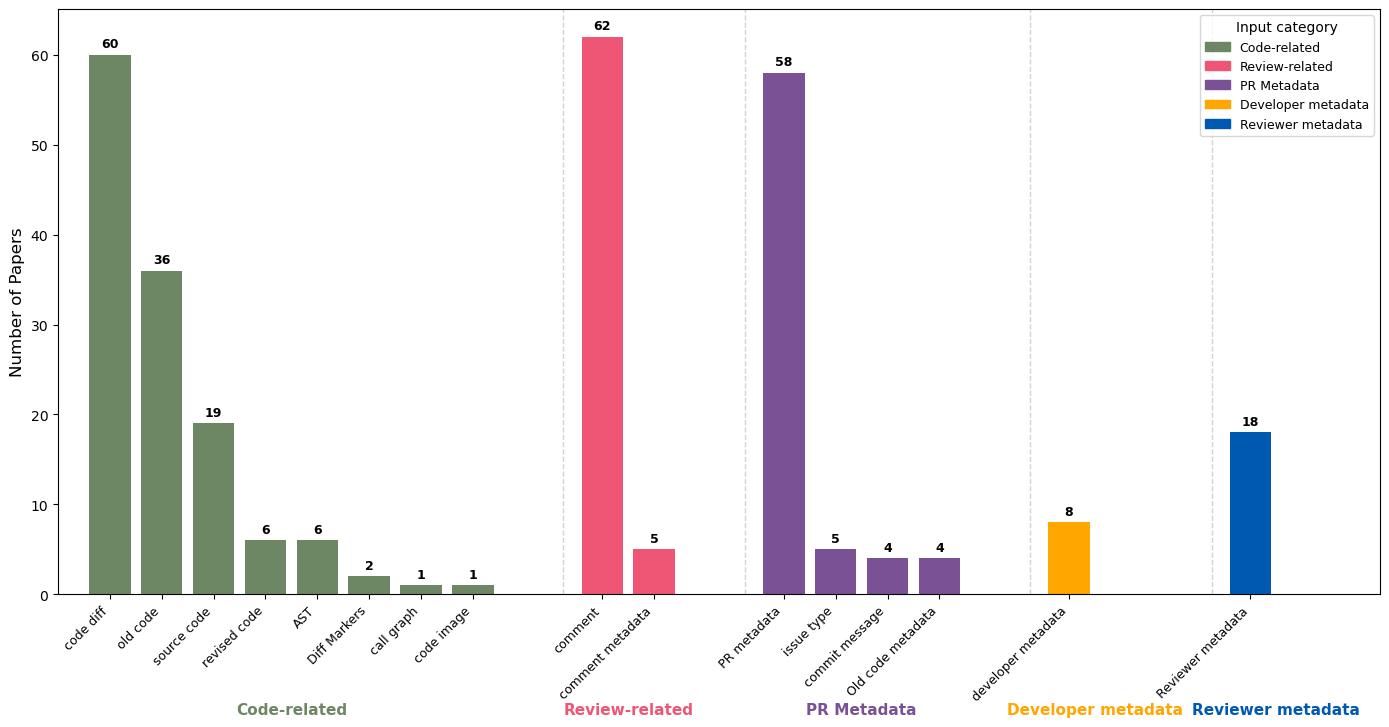

In [82]:
# Get counts for each input, filter out zeros
plot_data = []
for cat, items in category_items.items():
    for item in items:
        count = input_counts.get(item, 0)
        if count > 0:
            plot_data.append({"Input": item, "Count": count, "Category": cat})

plot_df = pd.DataFrame(plot_data)
plot_df = plot_df.sort_values(["Category", "Count"], ascending=[True, False])

# Create grouped bar chart
fig, ax = plt.subplots(figsize=(14, 8))

# Get unique categories and create positions
categories = list(category_items.keys())
category_colors = [INPUT_CATEGORY_COLORS[cat] for cat in categories]

# Group by category for plotting
x_positions = []
x_labels = []
colors = []
counts = []
current_x = 0
group_centers = []
group_start = []

for cat in categories:
    cat_data = plot_df[plot_df["Category"] == cat].sort_values("Count", ascending=False)
    group_start.append(current_x)
    n_items = len(cat_data)

    for i, (_, row) in enumerate(cat_data.iterrows()):
        x_positions.append(current_x)
        x_labels.append(row["Input"])
        colors.append(INPUT_CATEGORY_COLORS[cat])
        counts.append(row["Count"])
        current_x += 1


    # Minimum visual width per category (even if only 1 bar)
    min_group_width = 2

    group_width = max(n_items, min_group_width)
    group_centers.append(group_start[-1] + (group_width - 1) / 2)

    # Move x forward by group width
    current_x = group_start[-1] + group_width

    # Add gap between categories
    current_x += 1.5


# Plot bars
bars = ax.bar(x_positions, counts, color=colors, width=0.8)

# Add count labels on top of bars
for bar, count in zip(bars, counts):
    height = bar.get_height()
    ax.text(
        bar.get_x() + bar.get_width() / 2.0,
        height + 0.5,
        f"{count}",
        ha="center",
        va="bottom",
        fontsize=9,
        fontweight="bold",
    )

# Customize x-axis
ax.set_xticks(x_positions)
ax.set_xticklabels(x_labels, rotation=45, ha="right", fontsize=9)

# Add category labels below
ax.set_xlim(-1, current_x - 1)
y_min = ax.get_ylim()[0]

for i, (cat, center) in enumerate(zip(categories, group_centers)):
    # Add category label
    ax.text(
        center,
        -12,
        cat,
        ha="center",
        va="top",
        fontsize=11,
        fontweight="bold",
        color=INPUT_CATEGORY_COLORS[cat],
    )

    # Add separator line between groups (except after last)
    if i < len(categories) - 1:
        sep_x = group_start[i + 1] - 0.75
        ax.axvline(x=sep_x, color="#bdc3c7", linestyle="--", linewidth=1, alpha=0.7)

ax.set_ylabel("Number of Papers", fontsize=12)

# Legend
legend_patches = [
    mpatches.Patch(color=INPUT_CATEGORY_COLORS[cat], label=cat) for cat in categories
]
ax.legend(handles=legend_patches, loc="upper right", title="Input category", fontsize=9)


plt.tight_layout()
plt.subplots_adjust(bottom=0.25)
plt.savefig("./rq4_figures/inputs_frequency.pdf", bbox_inches="tight", dpi=300)
plt.show()


INPUT FEATURE FREQUENCY

Total unique input types: 20

  comment: 62 papers (37.6%)
  code diff: 60 papers (36.4%)
  PR metadata: 58 papers (35.2%)
  old code: 36 papers (21.8%)
  source code: 19 papers (11.5%)
  Reviewer metadata: 18 papers (10.9%)
  developer metadata: 8 papers (4.8%)
  revised code: 6 papers (3.6%)
  AST: 6 papers (3.6%)
  issue type: 5 papers (3.0%)
  comment metadata: 5 papers (3.0%)
  Old code metadata: 4 papers (2.4%)
  commit message: 4 papers (2.4%)
  Diff Markers: 2 papers (1.2%)
  Not mentioned: 1 papers (0.6%)
  Eye tracking data: 1 papers (0.6%)
  Cognitive load (ECG/HRV+pupillography): 1 papers (0.6%)
  code image: 1 papers (0.6%)
  call graph: 1 papers (0.6%)
  reviewer intention: 1 papers (0.6%)

CATEGORY COUNTS (UNIQUE PAPERS)
Code-related: 103 papers (62.4%)
Review-related: 64 papers (38.8%)
PR Metadata: 62 papers (37.6%)
Developer metadata: 8 papers (4.8%)
Reviewer metadata: 18 papers (10.9%)


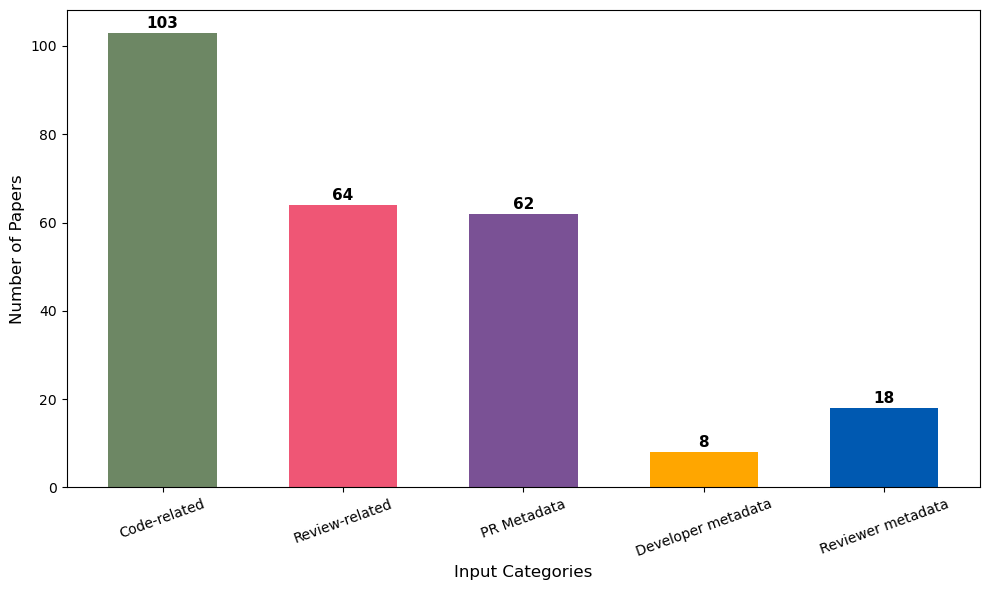


Sanity check:
Code-related: 103 unique papers
Review-related: 64 unique papers
PR Metadata: 62 unique papers
Developer metadata: 8 unique papers
Reviewer metadata: 18 unique papers


In [84]:
# FULL PIPELINE: Papers -> Categories -> 5-Bar Chart

import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter

# 1. Extract input counts (your original part - optional but kept)

all_inputs = []
for inputs in df["Input features"]:
    if isinstance(inputs, list):
        all_inputs.extend(inputs)
    elif pd.notna(inputs):
        all_inputs.append(inputs)

input_counts = Counter(all_inputs)

print("=" * 60)
print("INPUT FEATURE FREQUENCY")
print("=" * 60)
print(f"\nTotal unique input types: {len(input_counts)}\n")

for inp, count in sorted(input_counts.items(), key=lambda x: -x[1]):
    pct = count / len(df) * 100
    print(f"  {inp}: {count} papers ({pct:.1f}%)")

# 2. Map papers -> categories (NO DOUBLE COUNTING)

category_papers = {cat: set() for cat in category_items}

for idx, row in df.iterrows():
    inputs = row["Input features"]

    # Normalize to list
    if isinstance(inputs, list):
        paper_inputs = inputs
    elif pd.notna(inputs):
        paper_inputs = [inputs]
    else:
        paper_inputs = []

    # Assign paper to categories
    for cat, items in category_items.items():
        if any(inp in items for inp in paper_inputs):
            category_papers[cat].add(idx)  # idx = unique paper ID

# 3. Count unique papers per category

category_counts = {cat: len(papers) for cat, papers in category_papers.items()}

print("\n" + "=" * 60)
print("CATEGORY COUNTS (UNIQUE PAPERS)")
print("=" * 60)

for cat, count in category_counts.items():
    pct = count / len(df) * 100
    print(f"{cat}: {count} papers ({pct:.1f}%)")

# 4. Plot 5-bar chart (one per category)

categories = list(category_counts.keys())
counts = [category_counts[cat] for cat in categories]
colors = [INPUT_CATEGORY_COLORS[cat] for cat in categories]

fig, ax = plt.subplots(figsize=(10, 6))

bars = ax.bar(categories, counts, color=colors, width=0.6)

# Add labels on top of bars
for bar, count in zip(bars, counts):
    ax.text(
        bar.get_x() + bar.get_width() / 2.0,
        bar.get_height() + 0.5,
        f"{count}",
        ha="center",
        va="bottom",
        fontsize=11,
        fontweight="bold",
    )

# Axis labels
ax.set_ylabel("Number of Papers", fontsize=12)
ax.set_xlabel("Input Categories", fontsize=12)

# Rotate x labels for readability
plt.xticks(rotation=20)

# Clean layout
plt.tight_layout()

# Save figure
plt.savefig("./rq4_figures/inputs_category_5bars.pdf", bbox_inches="tight", dpi=300)

plt.show()

# 5. Sanity check (optional)

print("\nSanity check:")
for cat, papers in category_papers.items():
    print(f"{cat}: {len(papers)} unique papers")


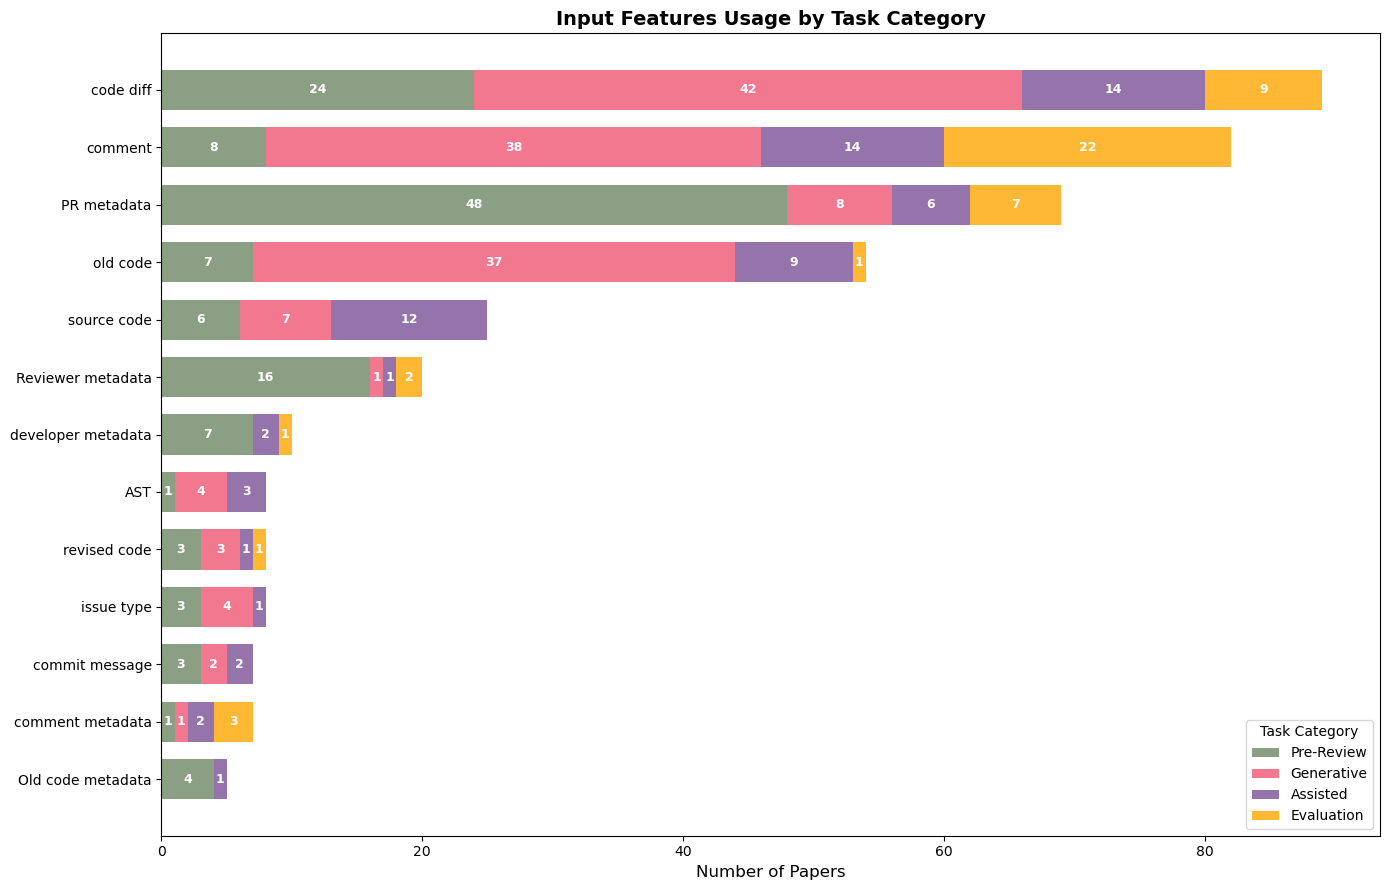

In [50]:
# 1.4 Individual Input Features Distribution by Task Category
# Each input can be used by multiple task categories - show this with stacked bars

# Build input-to-task-category usage matrix
input_task_usage = {}
for _, row in df.iterrows():
    tasks = row["Task"] if isinstance(row["Task"], list) else [row["Task"]]
    inputs = (
        row["Input features"]
        if isinstance(row["Input features"], list)
        else [row["Input features"]]
    )

    for inp in inputs:
        if inp and inp != "Not mentioned":
            if inp not in input_task_usage:
                input_task_usage[inp] = Counter()
            for task in tasks:
                if task:
                    task_cat = TASK_TO_CATEGORY.get(task, "Other")
                    input_task_usage[inp][task_cat] += 1

# Filter inputs with at least 3 papers and create DataFrame
input_task_df = pd.DataFrame(input_task_usage).T.fillna(0)
input_task_df["Total"] = input_task_df.sum(axis=1)
input_task_df = input_task_df[input_task_df["Total"] >= 3].sort_values(
    "Total", ascending=True
)

# Reorder columns for consistency
task_cat_order = ["Pre-Review", "Generative", "Assisted", "Evaluation"]
cols_to_plot = [c for c in task_cat_order if c in input_task_df.columns]

# Create stacked horizontal bar chart
fig, ax = plt.subplots(figsize=(14, 9))

y_pos = np.arange(len(input_task_df))
left = np.zeros(len(input_task_df))

for task_cat in cols_to_plot:
    values = input_task_df[task_cat].values
    color = TASK_CATEGORY_COLORS[task_cat]
    bars = ax.barh(
        y_pos,
        values,
        left=left,
        label=task_cat,
        color=color,
        linewidth=0.5,
        height=0.7,
        alpha=0.8,
    )
    left += values


# Add numbers inside stacked bars (hide zeros)
for container in ax.containers:
    labels = [f"{int(v)}" if v > 0 else "" for v in container.datavalues]
    ax.bar_label(
        container,
        labels=labels,
        label_type="center",
        fontsize=9,
        color="white",
        fontweight="bold",
    )


ax.set_yticks(y_pos)
ax.set_yticklabels(input_task_df.index, fontsize=10)
ax.set_xlabel("Number of Papers", fontsize=12)
ax.set_title("Input Features Usage by Task Category", fontsize=14, fontweight="bold")

# # Add total count labels at the end of each bar
# for i, total in enumerate(input_task_df['Total']):

# Legend with task category colors
ax.legend(title="Task Category", loc="lower right", fontsize=10)

plt.tight_layout()
plt.savefig("./rq4_figures/inputs_per_task.pdf", bbox_inches="tight", dpi=300)
plt.show()


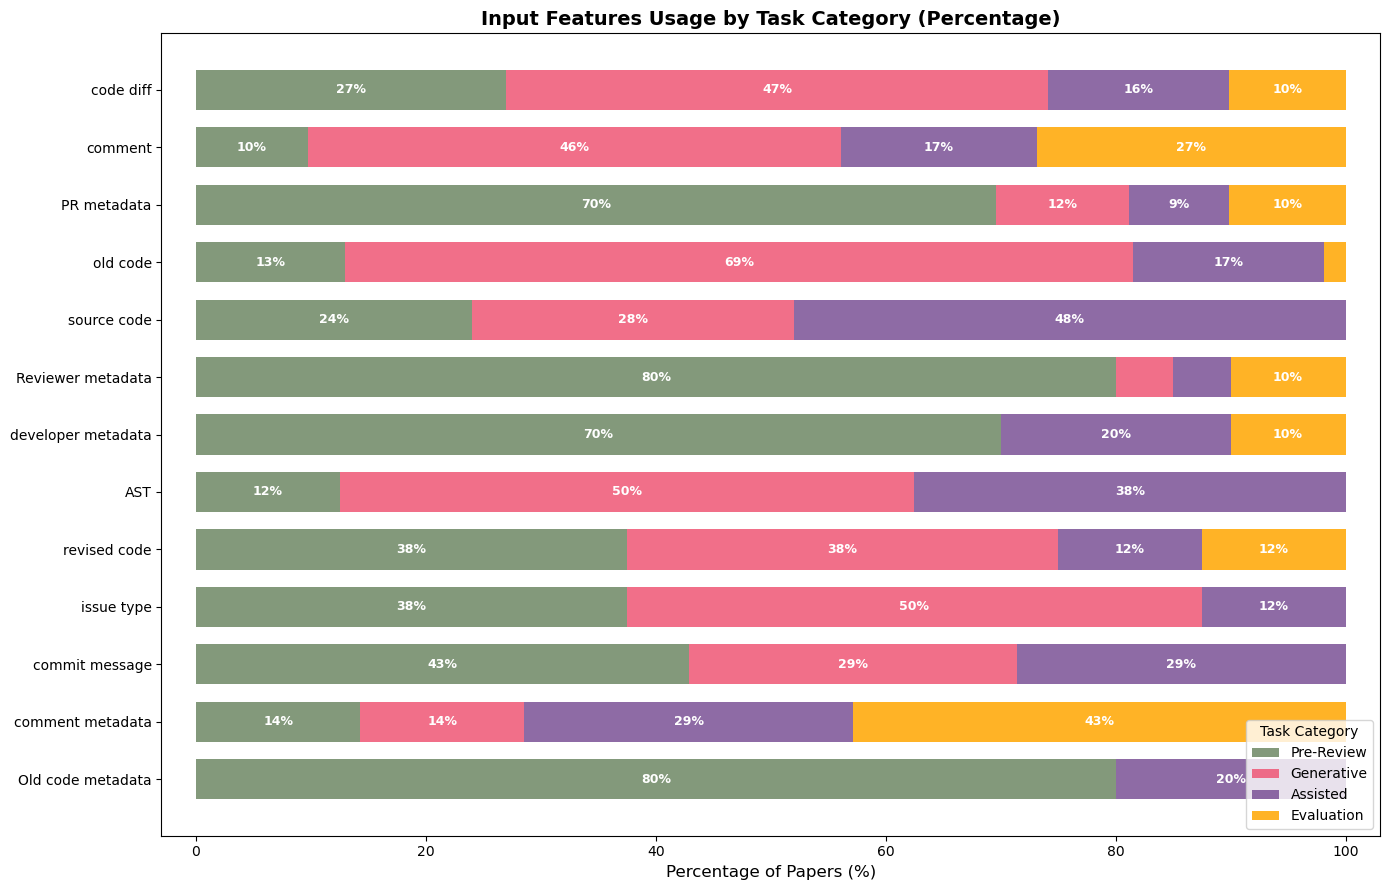

In [51]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter

# 1.4 Individual Input Features Distribution by Task Category (PERCENTAGE)
# Each input can be used by multiple task categories
# Show this with stacked horizontal bars normalized to 100%

# Build input-to-task-category usage matrix (COUNTS)
input_task_usage = {}

for _, row in df.iterrows():
    tasks = row["Task"] if isinstance(row["Task"], list) else [row["Task"]]
    inputs = (
        row["Input features"]
        if isinstance(row["Input features"], list)
        else [row["Input features"]]
    )

    for inp in inputs:
        if inp and inp != "Not mentioned":
            if inp not in input_task_usage:
                input_task_usage[inp] = Counter()

            for task in tasks:
                if task:
                    task_cat = TASK_TO_CATEGORY.get(task, "Other")
                    input_task_usage[inp][task_cat] += 1

# Create DataFrame and filter inputs with >= 3 papers
input_task_df = pd.DataFrame(input_task_usage).T.fillna(0)

input_task_df["Total"] = input_task_df.sum(axis=1)

input_task_df = input_task_df[input_task_df["Total"] >= 3].sort_values(
    "Total", ascending=True
)

# Column order (task categories)
task_cat_order = ["Pre-Review", "Generative", "Assisted", "Evaluation"]
cols_to_plot = [c for c in task_cat_order if c in input_task_df.columns]

# Convert COUNTS -> PERCENTAGES (row-wise)
input_task_pct = input_task_df[cols_to_plot].div(input_task_df["Total"], axis=0) * 100

# Plot stacked horizontal bar chart (PERCENTAGES)
fig, ax = plt.subplots(figsize=(14, 9))

y_pos = np.arange(len(input_task_pct))
left = np.zeros(len(input_task_pct))

for task_cat in cols_to_plot:
    values = input_task_pct[task_cat].values
    color = TASK_CATEGORY_COLORS[task_cat]

    ax.barh(
        y_pos, values, left=left, label=task_cat, color=color, height=0.7, alpha=0.85
    )

    left += values

# Axis formatting
ax.set_yticks(y_pos)
ax.set_yticklabels(input_task_pct.index, fontsize=10)

ax.set_xlabel("Percentage of Papers (%)", fontsize=12)
ax.set_xlim(0, 100)
pad = 3  # percentage points (tune: 2–5)
ax.set_xlim(-pad, 100 + pad)

ax.set_title(
    "Input Features Usage by Task Category (Percentage)", fontsize=14, fontweight="bold"
)

# Percentage labels inside bars (only if large enough)
for i, row in enumerate(input_task_pct.values):
    cumulative = 0
    for val in row:
        if val >= 7:  # avoid clutter
            ax.text(
                cumulative + val / 2,
                i,
                f"{val:.0f}%",
                ha="center",
                va="center",
                fontsize=9,
                color="white",
                fontweight="bold",
            )
        cumulative += val

# Legend
ax.legend(title="Task Category", loc="lower right", fontsize=10)

plt.tight_layout()
plt.savefig("./rq4_figures/inputs_per_task_percentage.pdf", dpi=300)
plt.show()


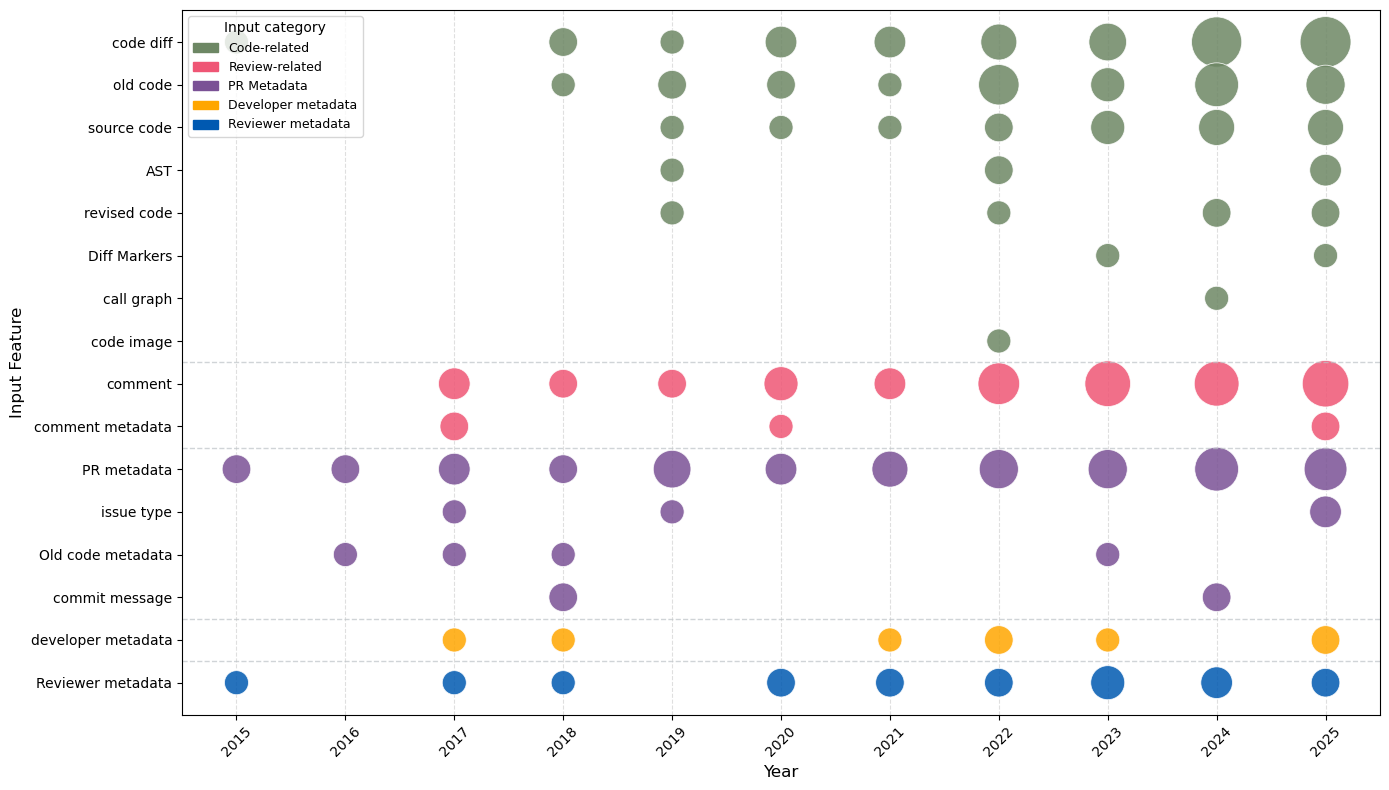

In [52]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np

# 1. Extract Input Features per Paper (RAW → LONG FORMAT)

rows = []

for _, row in df.iterrows():
    year = row["Year"]
    inputs = row["Input features"]

    if isinstance(inputs, list):
        input_list = inputs
    elif inputs:
        input_list = [inputs]
    else:
        continue

    for inp in input_list:
        rows.append({"Year": year, "Input": inp})

df_inputs = pd.DataFrame(rows)

# 2. Assign Category to Each Input

input_to_category = {}
for cat, items in category_items.items():
    for item in items:
        input_to_category[item] = cat

df_inputs["Category"] = df_inputs["Input"].map(input_to_category)

# Safety: drop inputs not in taxonomy
df_inputs = df_inputs.dropna(subset=["Category"])

# 3. Aggregate Counts (Year × Category × Input)

plot_df = (
    df_inputs.groupby(["Year", "Category", "Input"]).size().reset_index(name="Count")
)

# 4. Enforce Input Ordering (Grouped by Category, Frequency-Based)

categories = list(category_items.keys())

ordered_inputs = []
for cat in categories:
    cat_inputs = (
        plot_df[plot_df["Category"] == cat]
        .groupby("Input")["Count"]
        .sum()
        .sort_values(ascending=False)
        .index.tolist()
    )
    ordered_inputs.extend(cat_inputs)

# Remove duplicates while preserving order
ordered_inputs = list(dict.fromkeys(ordered_inputs))

plot_df["Input"] = pd.Categorical(
    plot_df["Input"], categories=ordered_inputs, ordered=True
)

plot_df = plot_df.sort_values(["Input", "Year"])

# 5. Bubble Chart (FLIPPED AXES)

fig, ax = plt.subplots(figsize=(14, 8))

USE_SQRT = True
SIZE_SCALE = 300  # only used if USE_SQRT = False

for cat in categories:
    subset = plot_df[plot_df["Category"] == cat]

    if subset.empty:
        continue

    if USE_SQRT:
        sizes = np.sqrt(subset["Count"]) * 300
    else:
        sizes = subset["Count"] * SIZE_SCALE

    ax.scatter(
        subset["Year"],  # X-axis
        subset["Input"],  # Y-axis (categorical)
        s=sizes,
        color=INPUT_CATEGORY_COLORS[cat],
        alpha=0.85,
        edgecolors="white",
        linewidth=0.6,
    )

# 6. Axes, Ticks, Grid

years = sorted(plot_df["Year"].unique())
ax.set_xticks(years)
ax.set_xticklabels(years, rotation=45)

ax.set_xlabel("Year", fontsize=12)
ax.set_ylabel("Input Feature", fontsize=12)

# Match task-style categorical layout
ax.invert_yaxis()

ax.grid(True, axis="x", linestyle="--", alpha=0.4)
ax.set_axisbelow(True)

# 7. Category Labels & Separators (Y-axis)

# Map inputs to y-indices
input_positions = {inp: i for i, inp in enumerate(ordered_inputs)}

for i, cat in enumerate(categories):
    cat_inputs = [inp for inp in ordered_inputs if input_to_category.get(inp) == cat]

    if not cat_inputs:
        continue

    y_indices = [input_positions[inp] for inp in cat_inputs]
    y_center = np.mean(y_indices)

    # # Category label (left side)
    # ax.text(
    # )

    # Horizontal separator
    if i < len(categories) - 1:
        sep_y = max(y_indices) + 0.5
        ax.axhline(
            y=sep_y,
            color="#bdc3c7",
            linestyle="--",
            linewidth=1,
            alpha=0.7,
        )

# 8. Legend

legend_patches = [
    mpatches.Patch(color=INPUT_CATEGORY_COLORS[cat], label=cat) for cat in categories
]

ax.legend(
    handles=legend_patches,
    title="Input category",
    loc="upper left",
    fontsize=9,
)

# 9. Save & Show

plt.tight_layout()
plt.savefig(
    "./rq4_figures/inputs_bubble_years_flipped.pdf",
    bbox_inches="tight",
    dpi=300,
)
plt.show()


In [53]:
plot_df.groupby("Category")["Count"].sum()


Category
Code-related          131
Developer metadata      8
PR Metadata            71
Review-related         67
Reviewer metadata      18
Name: Count, dtype: int64

In [71]:
import plotly.graph_objects as go
from collections import Counter

# Build Input → Task Category flows
input_to_task = Counter()

for _, row in df.iterrows():
    inputs = row["Input features"]
    tasks = row["Task"]

    for inp in inputs:
        if not inp or inp == "Not mentioned":
            continue

        for task in tasks:
            if not task:
                continue

            task_cat = TASK_TO_CATEGORY.get(task, "Other")
            input_to_task[(inp, task_cat)] += 1

# Nodes
inputs = sorted({k[0] for k in input_to_task})
task_cats = sorted({k[1] for k in input_to_task})

node_labels = inputs + task_cats
node_index = {label: i for i, label in enumerate(node_labels)}

# Links
sources = []
targets = []
values = []
link_colors = []

for (inp, task_cat), count in input_to_task.items():
    sources.append(node_index[inp])
    targets.append(node_index[task_cat])
    values.append(count)
    link_colors.append(TASK_CATEGORY_COLORS.get(task_cat, "#999999"))

# Node colors (FORCED for task categories)
node_colors = ["#ecf0f1"] * len(inputs) + [  # Inputs (neutral)
    TASK_CATEGORY_COLORS[t] for t in task_cats
]  # Task categories (FORCED)

# Plot Sankey
fig = go.Figure(
    go.Sankey(
        arrangement="snap",
        node=dict(
            label=node_labels,
            color=node_colors,
            pad=20,
            thickness=18,
            line=dict(color="black", width=0.3),
        ),
        link=dict(source=sources, target=targets, value=values, color=link_colors),
    )
)

fig.update_layout(
    title="Input Features → Task Categories", font_size=16, width=1100, height=650
)

fig.show()


In [72]:
import plotly.io as pio

pio.renderers.default = "browser"


In [73]:
fig.write_html("sankey_inputs_tasks.html")


In [76]:
import plotly.graph_objects as go
import numpy as np
from collections import Counter

# REQUIRED INPUTS (must already exist)
# TASK_TO_CATEGORY     : dict { task -> category }
# TASK_CATEGORY_COLORS : dict { category -> color }

# 1. Build Input → Task flows
input_to_task = Counter()

for _, row in df.iterrows():
    inputs = row["Input features"]
    tasks = row["Task"]

    for inp in inputs:
        if not inp or inp == "Not mentioned":
            continue

        for task in tasks:
            if not task:
                continue

            input_to_task[(inp, task)] += 1

# 2. Collect nodes
inputs = sorted({k[0] for k in input_to_task})
tasks = list({k[1] for k in input_to_task})

# 3. Rank tasks by (category → frequency)
TASK_CATEGORY_ORDER = ["Pre-Review", "Generative", "Assisted", "Evaluation"]

task_total_flow = {
    task: sum(v for (i, t), v in input_to_task.items() if t == task) for task in tasks
}

tasks_sorted = sorted(
    tasks,
    key=lambda t: (
        TASK_CATEGORY_ORDER.index(TASK_TO_CATEGORY.get(t, "Other")),
        -task_total_flow[t],
    ),
)

# 4. Build node list (LEFT → RIGHT)
node_labels = inputs + tasks_sorted
node_index = {label: i for i, label in enumerate(node_labels)}

# 5. Build links
sources = []
targets = []
values = []
link_colors = []

for (inp, task), count in input_to_task.items():
    sources.append(node_index[inp])
    targets.append(node_index[task])
    values.append(count)

    task_cat = TASK_TO_CATEGORY.get(task, "Other")
    link_colors.append(TASK_CATEGORY_COLORS.get(task_cat, "#999999"))

# 6. Node colors
input_colors = ["#ecf0f1"] * len(inputs)

task_colors = [
    TASK_CATEGORY_COLORS.get(TASK_TO_CATEGORY.get(task, "Other"), "#999999")
    for task in tasks_sorted
]

node_colors = input_colors + task_colors

# 7. FORCE node positions (THIS IS THE KEY)
n_inputs = len(inputs)
n_tasks = len(tasks_sorted)

# Inputs: fixed on the left
input_x = [0.01] * n_inputs
input_y = np.linspace(0.05, 0.95, n_inputs)

# Tasks: fixed on the right, ORDERED TOP → BOTTOM
task_x = [0.99] * n_tasks
task_y = np.linspace(0.05, 0.95, n_tasks)

node_x = input_x + task_x
node_y = list(input_y) + list(task_y)

# 8. Plot Sankey (FULLY FIXED)
fig = go.Figure(
    go.Sankey(
        arrangement="fixed",
        node=dict(
            label=node_labels,
            color=node_colors,
            x=node_x,
            y=node_y,
            pad=20,
            thickness=18,
            line=dict(color="black", width=0.3),
        ),
        link=dict(source=sources, target=targets, value=values, color=link_colors),
    )
)

fig.update_layout(
    font_size=16,
    width=1600,
    height=900,
)

config = {
    "toImageButtonOptions": {
        "format": "png",  # or "svg" (recommended)
        "filename": "sankey_inputs_tasks",
        "width": 1600,
        "height": 900,
        "scale": 6,  # ✅ THIS is where scale belongs
    }
}

fig.show(config=config)


In [75]:
fig.write_html("sankey_inputs_tasks.html")


In [58]:
# 3.2 All Datasets

print("=" * 60)
print("ALL DATASETS")
print("=" * 60)

# Count dataset usage (handle comma-separated datasets)
dataset_usage = Counter()
for ds in df["Dataset"]:
    if pd.notna(ds) and ds:
        # Some entries have multiple datasets separated by comma
        datasets = [d.strip() for d in str(ds).split(",") if d.strip()]
        for d in datasets:
            dataset_usage[d] += 1

print(f"\nTotal unique datasets: {len(dataset_usage)}")
print(f"\nAll datasets:")
print("-" * 40)

for ds, count in dataset_usage.most_common(1000):
    print(f"  {ds}: {count} papers")


ALL DATASETS

Total unique datasets: 81

All datasets:
----------------------------------------
  Microsoft: 21 papers
  Tufano dataset: 9 papers
  CodeReviewNER: 3 papers
  RevHelper: 2 papers
  BigCloneBench: 2 papers
  GHTorrent: 2 papers
  SARD: 2 papers
  TufanoDataset2: 2 papers
  AutoTransform: 2 papers
  ToxiCR: 2 papers
  D-ACT: 2 papers
  CodeReview-New (CRN): 2 papers
  StackExchange: 2 papers
  CRUsefulness: 2 papers
  CuREV: 2 papers
  RevFinder: 1 papers
  CR defectiveness: 1 papers
  ReviewerRecom: 1 papers
  SentiCR: 1 papers
  DTPre: 1 papers
  DupPR: 1 papers
  PublicGitArchive: 1 papers
  CRLinkage: 1 papers
  Gerrit: 1 papers
  Core: 1 papers
  EfficiencyDataset: 1 papers
  CCFlex: 1 papers
  SystematicLabelBias: 1 papers
  CROP: 1 papers
  AUGER: 1 papers
  CoditT5: 1 papers
  CLMN: 1 papers
  DeepLineDP: 1 papers
  Detecting Interpersonal Conflict: 1 papers
  Predict-Code-Changes: 1 papers
  RAR_recommender: 1 papers
  BiometricCR: 1 papers
  Review4Repair: 1 pape

In [59]:
# 3.2 Most Used Datasets

print("=" * 60)
print("MOST USED DATASETS")
print("=" * 60)

# Count dataset usage (handle comma-separated datasets)
dataset_usage = Counter()
for ds in df["Dataset"]:
    if pd.notna(ds) and ds:
        # Some entries have multiple datasets separated by comma
        datasets = [d.strip() for d in str(ds).split(",") if d.strip()]
        for d in datasets:
            dataset_usage[d] += 1

print(f"\nTotal unique datasets: {len(dataset_usage)}")
print(f"\nTop 15 most used datasets:")
print("-" * 40)

for ds, count in dataset_usage.most_common(15):
    print(f"  {ds}: {count} papers")


MOST USED DATASETS

Total unique datasets: 81

Top 15 most used datasets:
----------------------------------------
  Microsoft: 21 papers
  Tufano dataset: 9 papers
  CodeReviewNER: 3 papers
  RevHelper: 2 papers
  BigCloneBench: 2 papers
  GHTorrent: 2 papers
  SARD: 2 papers
  TufanoDataset2: 2 papers
  AutoTransform: 2 papers
  ToxiCR: 2 papers
  D-ACT: 2 papers
  CodeReview-New (CRN): 2 papers
  StackExchange: 2 papers
  CRUsefulness: 2 papers
  CuREV: 2 papers


In [60]:
# Dataset renaming dictionary (canonical names)
DATASET_RENAME_MAP = {
    # SWE-bench variants
    "Microsoft": "CodeReviewer",
    "Tufano dataset": "BCRA",
    "TufanoDataset2": "ACA",
}


In [61]:
import pandas as pd

dataset_rows = []


def normalize_dataset_name(name):
    return DATASET_RENAME_MAP.get(name.strip(), name.strip())


for raw_name, freq in dataset_usage.items():
    dataset_rows.append(
        {
            "Dataset_raw": raw_name,
            "Dataset_norm": normalize_dataset_name(raw_name),
            "Frequency": freq,
        }
    )

dataset_df = pd.DataFrame(dataset_rows)


In [62]:
dataset_df.head(60)


,Dataset_raw,Dataset_norm,Frequency
0,RevFinder,RevFinder,1
1,CR defectiveness,CR defectiveness,1
2,ReviewerRecom,ReviewerRecom,1
3,SentiCR,SentiCR,1
4,RevHelper,RevHelper,2
5,DTPre,DTPre,1
6,BigCloneBench,BigCloneBench,2
7,DupPR,DupPR,1
8,GHTorrent,GHTorrent,2
9,PublicGitArchive,PublicGitArchive,1


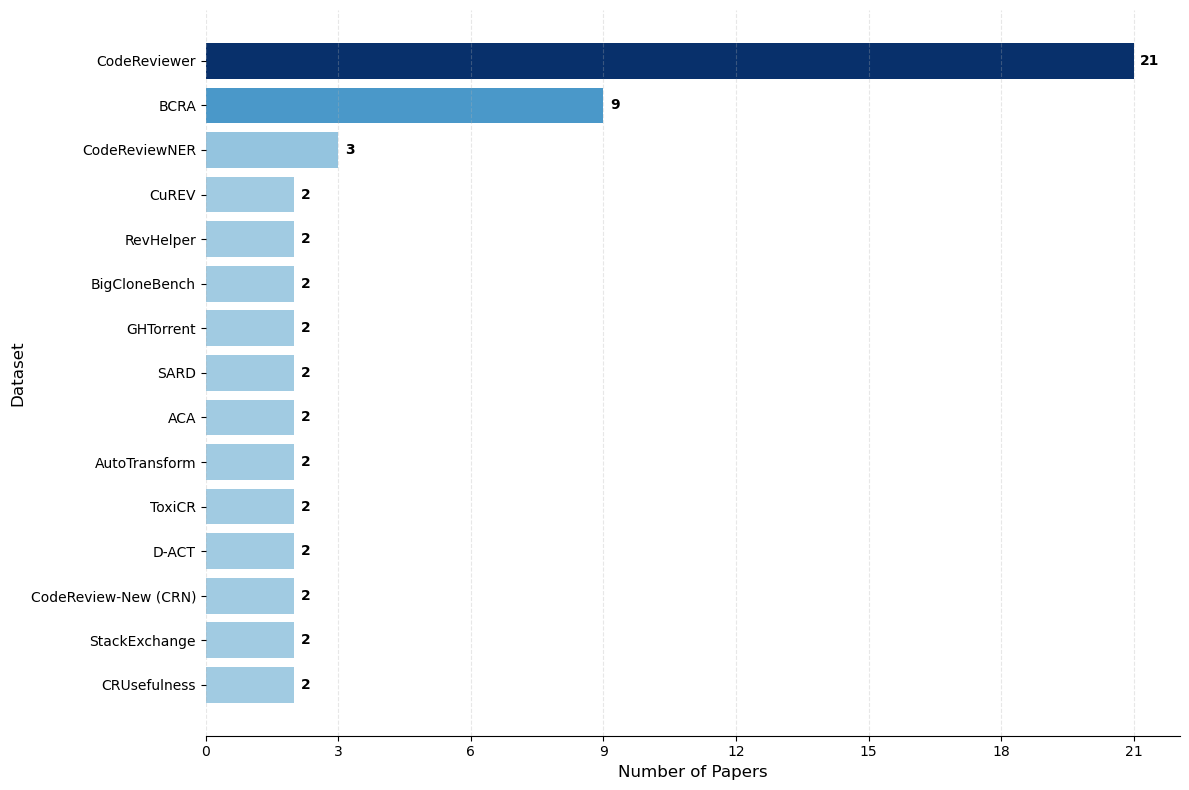

In [63]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from matplotlib.ticker import MaxNLocator

# ASSUMES:
# dataset_df with columns:

TARGET_DATASET = "CuREV"  # exact name as in Dataset_raw
MIN_FREQ = 1

# 1. Filter + sort by frequency (descending)
plot_df = (
    dataset_df.query("Frequency > @MIN_FREQ")
    .sort_values("Frequency", ascending=False)
    .reset_index(drop=True)
)

# 2. Force CuREV to be 4th (index = 3)
if TARGET_DATASET in plot_df["Dataset_norm"].values:
    curev_row = plot_df[plot_df["Dataset_norm"] == TARGET_DATASET]
    plot_df = plot_df[plot_df["Dataset_norm"] != TARGET_DATASET]

    insert_pos = min(3, len(plot_df))  # safety
    plot_df = pd.concat(
        [plot_df.iloc[:insert_pos], curev_row, plot_df.iloc[insert_pos:]],
        ignore_index=True,
    )

# 3. Seaborn palette (reversed Greens for emphasis)
palette = sns.color_palette("Greens_r", n_colors=len(plot_df))

max_count = plot_df["Frequency"].max()
norm = plot_df["Frequency"].to_numpy() / max_count
palette = plt.cm.Blues(0.3 + 0.7 * norm)
# 4. Horizontal bar chart
fig, ax = plt.subplots(figsize=(12, 8))

bars = ax.barh(
    plot_df["Dataset_norm"], plot_df["Frequency"], color=palette, edgecolor="none"
)

ax.invert_yaxis()  # top = first row

# 5. Integer labels + integer x-axis
for bar in bars:
    width = int(bar.get_width())
    ax.text(
        width + 0.15,
        bar.get_y() + bar.get_height() / 2,
        f"{width}",
        va="center",
        fontsize=10,
        fontweight="bold",
    )

ax.xaxis.set_major_locator(MaxNLocator(integer=True))

# 6. Styling
ax.set_xlabel("Number of Papers", fontsize=12)
ax.set_ylabel("Dataset", fontsize=12)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_visible(False)
ax.grid(axis="x", linestyle="--", alpha=0.3)

plt.tight_layout()

# 7. Save & show
plt.savefig(
    "./rq4_figures/top_datasets_raw_frequency.pdf", dpi=300, bbox_inches="tight"
)
plt.show()


DATASET AVAILABILITY TRENDS OVER TIME
      Not available  Partially available  Available
Year                                               
2015              2                    1          0
2016              1                    0          2
2017              3                    0          3
2018              4                    0          1
2019              6                    2          3
2020              7                    1          4
2021              5                    1          3
2022              6                    0         15
2023              6                    3         15
2024              6                    4         27
2025              9                    3         22


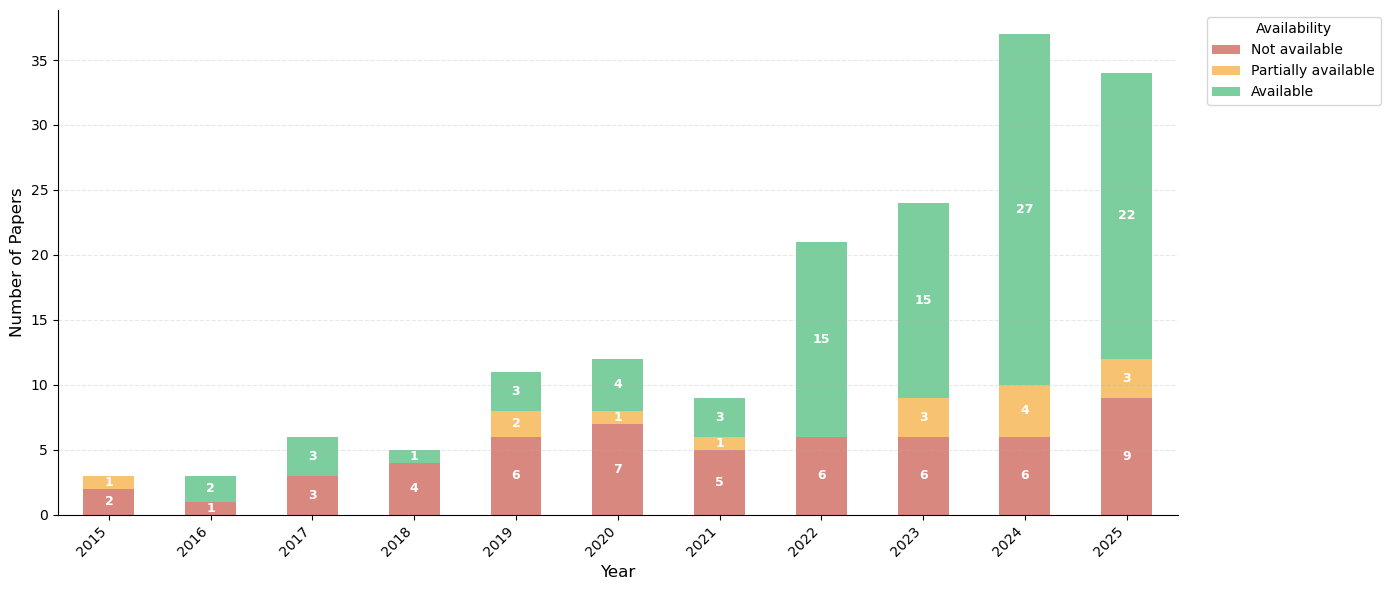

In [64]:
import matplotlib.pyplot as plt
import pandas as pd

# 4.1 Dataset Availability Trends Over Time

print("=" * 60)
print("DATASET AVAILABILITY TRENDS OVER TIME")
print("=" * 60)

# 1. Aggregate data
yearly_availability = (
    df.groupby(["Year", "Dataset availability"]).size().unstack(fill_value=0)
)

# 2. Force column order (BOTTOM → TOP)
availability_order = ["not available", "partially available", "available"]

yearly_availability = yearly_availability.reindex(
    columns=availability_order, fill_value=0
)

# 3. Capitalize first word only (for display)
yearly_availability.columns = [col.capitalize() for col in yearly_availability.columns]

print(yearly_availability)

# 4. Define colors WITH transparency (RGBA)
colors = {
    "Available": (39 / 255, 174 / 255, 96 / 255, 0.8),
    "Partially available": (243 / 255, 156 / 255, 18 / 255, 0.8),
    "Not available": (192 / 255, 57 / 255, 43 / 255, 0.8),
}

plot_colors = [colors[c] for c in yearly_availability.columns]

# 5. Stacked bar chart
fig, ax = plt.subplots(figsize=(14, 6))

yearly_availability.plot(kind="bar", stacked=True, ax=ax, color=plot_colors, alpha=0.6)

# Add numbers inside stacked bars (HIDE zeros)
for container in ax.containers:
    labels = [f"{int(v)}" if v > 0 else "" for v in container.datavalues]
    ax.bar_label(
        container,
        labels=labels,
        label_type="center",
        fontsize=9,
        color="white",
        fontweight="bold",
    )

# 6. Formatting
ax.set_xlabel("Year", fontsize=12)
ax.set_ylabel("Number of Papers", fontsize=12)

ax.legend(title="Availability", bbox_to_anchor=(1.02, 1), loc="upper left")

ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha="right")

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.grid(axis="y", linestyle="--", alpha=0.3)

plt.tight_layout()

# 7. Save & show
plt.savefig("./rq4_figures/datasets_Availability.pdf", bbox_inches="tight", dpi=300)

plt.show()


PRE-PROCESSING AND ENCODING TECHNIQUES

Unique pre-processing techniques: 21

Top 15 pre-processing techniques:
  filtering: 69 papers (41.8%)
  tokenization: 59 papers (35.8%)
  feature extraction: 47 papers (28.5%)
  cleaning: 43 papers (26.1%)
  Feature selection: 16 papers (9.7%)
  dataset balancing: 15 papers (9.1%)
  dataset curation: 14 papers (8.5%)
  stop words removal: 12 papers (7.3%)
  stemming: 10 papers (6.1%)
  padding: 9 papers (5.5%)
  data augmentation: 8 papers (4.8%)
  lemmatization: 8 papers (4.8%)
  scaling: 6 papers (3.6%)
  Byte-Pair Encoding (BPE): 6 papers (3.6%)
  truncation: 5 papers (3.0%)

Unique encoding techniques: 31

Top 15 encoding techniques:
  Word2vec: 18 papers (10.9%)
  TFIDF: 14 papers (8.5%)
  BERT: 10 papers (6.1%)
  BoW: 8 papers (4.8%)
  CodeBERT: 6 papers (3.6%)
  RobertaTokenizer: 5 papers (3.0%)
  CodeT5: 5 papers (3.0%)
  Count Encoding: 3 papers (1.8%)
  One-hot encoding: 3 papers (1.8%)
  n-grams: 3 papers (1.8%)
  fastText: 3 papers (

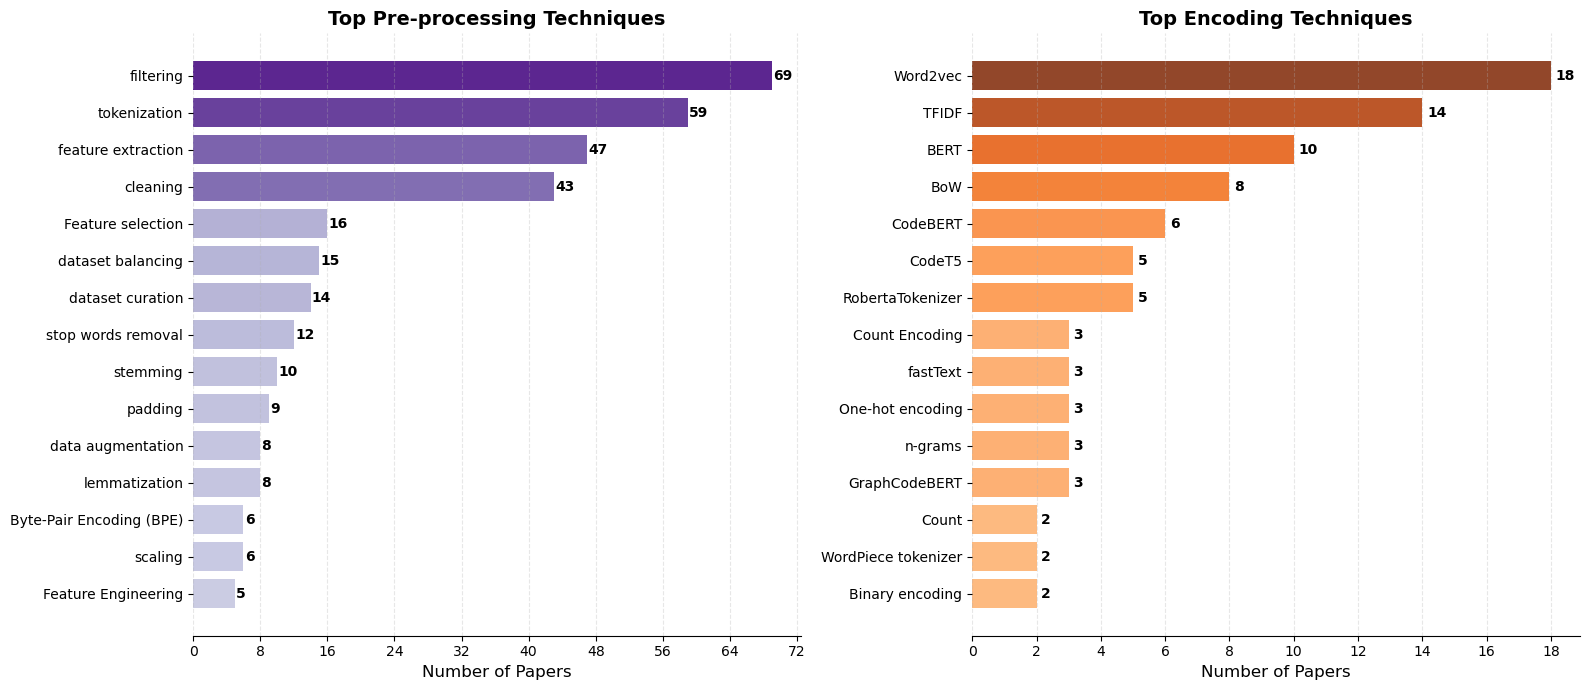

In [65]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from collections import Counter
from matplotlib.ticker import MaxNLocator

# 4.3 + 4.4 Pre-processing and Encoding Techniques

print("=" * 60)
print("PRE-PROCESSING AND ENCODING TECHNIQUES")
print("=" * 60)

# 1. Build PRE-PROCESSING counts
all_preproc = []
for procs in df["Pre-processing techniques"]:
    if isinstance(procs, list):
        all_preproc.extend([p for p in procs if p])
    elif procs:
        all_preproc.append(procs)

preproc_counts = Counter(all_preproc)

print(f"\nUnique pre-processing techniques: {len(preproc_counts)}")
print("\nTop 15 pre-processing techniques:")
for proc, count in preproc_counts.most_common(15):
    pct = count / len(df) * 100
    print(f"  {proc}: {count} papers ({pct:.1f}%)")

# 2. Build ENCODING counts
all_encoding = []
for encs in df["Encoding techniques"]:
    if isinstance(encs, list):
        all_encoding.extend([e for e in encs if e])
    elif encs:
        all_encoding.append(encs)

encoding_counts = Counter(all_encoding)

print(f"\nUnique encoding techniques: {len(encoding_counts)}")
print("\nTop 15 encoding techniques:")
for enc, count in encoding_counts.most_common(15):
    pct = count / len(df) * 100
    print(f"  {enc}: {count} papers ({pct:.1f}%)")

# 4.4 Visualization: Pre-processing and Encoding

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# Pre-processing techniques plot
ax1 = axes[0]

preproc_df = (
    pd.DataFrame(preproc_counts.items(), columns=["Technique", "Count"])
    .sort_values("Count", ascending=True)
    .tail(15)
)

colors1 = plt.cm.Purples(0.3 + 0.7 * (preproc_df["Count"] / preproc_df["Count"].max()))

ax1.barh(
    preproc_df["Technique"],
    preproc_df["Count"],
    color=colors1,
    edgecolor="none",
    alpha=0.85,
)

for bar in ax1.patches:
    width = int(bar.get_width())
    ax1.text(
        width + 0.15,
        bar.get_y() + bar.get_height() / 2,
        f"{width}",
        va="center",
        fontsize=10,
        fontweight="bold",
    )


ax1.set_xlabel("Number of Papers", fontsize=12)
ax1.set_title("Top Pre-processing Techniques", fontsize=14, fontweight="bold")
ax1.xaxis.set_major_locator(MaxNLocator(integer=True))

ax1.spines["top"].set_visible(False)
ax1.spines["right"].set_visible(False)
ax1.spines["left"].set_visible(False)
ax1.grid(axis="x", linestyle="--", alpha=0.3)

# Encoding techniques plot
ax2 = axes[1]

encoding_df = (
    pd.DataFrame(encoding_counts.items(), columns=["Technique", "Count"])
    .sort_values("Count", ascending=True)
    .tail(15)
)

colors2 = plt.cm.Oranges(
    0.3 + 0.7 * (encoding_df["Count"] / encoding_df["Count"].max())
)

ax2.barh(
    encoding_df["Technique"],
    encoding_df["Count"],
    color=colors2,
    edgecolor="none",
    alpha=0.85,
)

for bar in ax2.patches:
    width = int(bar.get_width())
    ax2.text(
        width + 0.15,
        bar.get_y() + bar.get_height() / 2,
        f"{width}",
        va="center",
        fontsize=10,
        fontweight="bold",
    )


ax2.set_xlabel("Number of Papers", fontsize=12)
ax2.set_title("Top Encoding Techniques", fontsize=14, fontweight="bold")
ax2.xaxis.set_major_locator(MaxNLocator(integer=True))

ax2.spines["top"].set_visible(False)
ax2.spines["right"].set_visible(False)
ax2.spines["left"].set_visible(False)
ax2.grid(axis="x", linestyle="--", alpha=0.3)

plt.tight_layout()

plt.savefig("./rq4_figures/preprocessing_techniques.pdf", bbox_inches="tight", dpi=300)

plt.show()
